# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

In [2]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [3]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [4]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

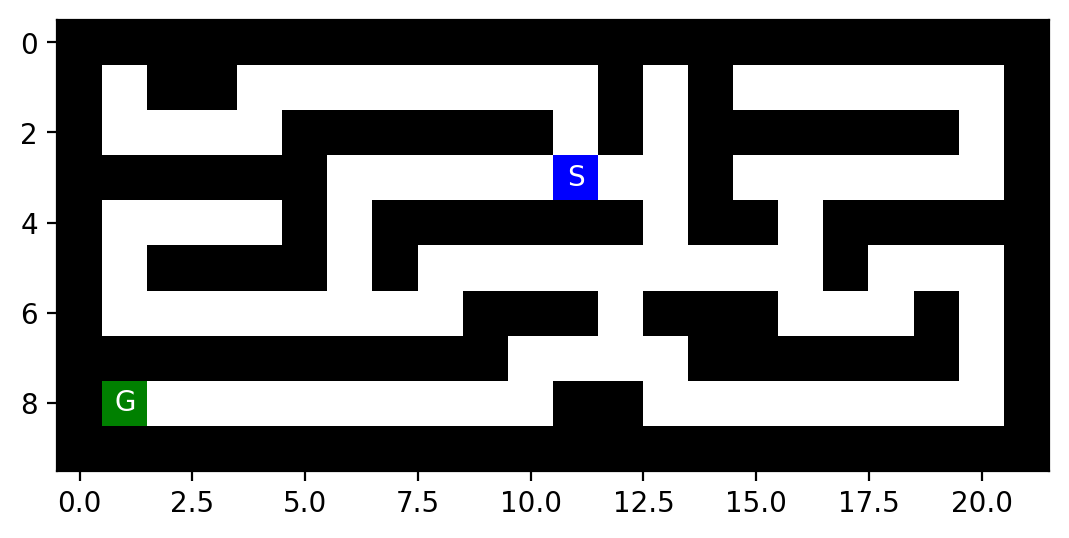

In [5]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [6]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [7]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x, y).

        Para

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [8]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [9]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['E', 'S', 'W', 'W', 'N', 'N', 'N', 'E', 'W', 'E']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [10]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: S
Following plan... step 1: W
Following plan... step 2: W
Following plan... step 3: N
Following plan... step 4: W
Following plan... step 5: W
Following plan... step 6: N
Following plan... step 7: N
Following plan... step 8: S
Following plan... step 9: S
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [11]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [medium maze](medium_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

**Định nghĩa bài toán tìm kiếm (mê cung)**

- **Initial state (trạng thái đầu):** vị trí ô `S`, biểu diễn bằng cặp `(row, col)`.
- **Actions (hành động):** `{N, E, S, W}` (lên, phải, xuống, trái). Một hành động chỉ hợp lệ nếu ô đích không phải tường `X`.
- **Transition model (mô hình chuyển trạng thái):** `RESULT((r,c), a) = (r+Δr, c+Δc)` với
  `N: (-1,0)`, `E: (0,+1)`, `S: (+1,0)`, `W: (0,-1)`. Mô hình xác định (deterministic): cùng một trạng thái và hành động luôn cho cùng một kết quả.
- **Goal state (trạng thái đích):** vị trí ô `G`. Kiểm tra đích: `s == goal`.
- **Path cost (chi phí đường đi):** mỗi bước có chi phí 1, nên `g(n)` = số bước từ gốc đến `n` = độ sâu của nút `n`.

Môi trường: quan sát đầy đủ, rời rạc, xác định và đã biết (agent có bản đồ).

Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

**Ước lượng kích thước bài toán**

- **n (kích thước không gian trạng thái):** số ô không phải tường (`!= 'X'`), gồm cả `S` và `G`. Đây cũng là chặn trên của số trạng thái khác nhau.
- **d (độ sâu lời giải tối ưu):** độ dài đường đi ngắn nhất từ `S` đến `G`. Vì mọi bước đều có chi phí 1, BFS cho đúng giá trị này.
- **m (độ sâu tối đa của cây):** nếu có `reached` (BFS, A*), m ≤ n − 1. Nếu không có `reached` (DFS chỉ kiểm tra chu trình trên đường đi hiện tại), m cũng bị chặn bởi n − 1 vì không có ô nào lặp lại trên một đường. Tuy vậy cây có thể rất lớn, vì cùng một ô được thăm lại qua nhiều đường khác nhau.
- **b (hệ số phân nhánh tối đa):** tối đa 4 (4 hướng). Với nút không phải gốc, một hướng quay lại ô cha nên thực tế thường ≤ 3.

**Cách xác định cho một mê cung cụ thể**

1. Đọc file và `parse_maze` thành mảng numpy.
2. n = đếm số ô khác `'X'`: `n = (maze != 'X').sum()`.
3. d = chạy BFS từ `S` đến `G`, lấy `cost` của nút đích.
4. m = lấy độ sâu lớn nhất ghi nhận trong lúc chạy (biến `max_depth`). Chặn trên lý thuyết là n − 1.
5. b = với mỗi ô trống, đếm số hàng xóm (4 hướng) không phải tường, lấy giá trị lớn nhất.

| Maze | n | d | b (tối đa) |
|---|---|---|---|
| small | 94 | 19 | 3 |
| medium | 274 | 68 | 3 |
| large | 647 | 210 | 4 |
| open | 684 | 54 | 4 |
| L | 157 | 16 | 4 |
| loops | 72 | 23 | 4 |
| empty | 100 | 14 | 4 |
| empty_2 | 100 | 14 | 4 |

Nhận xét: maze rỗng và maze mở (`open`, `empty`) có b lớn và nhiều đường đi cùng độ dài, nên cây tìm kiếm rất lớn nếu không có `reached`. Đây là lý do DFS gặp khó ở các maze đó.

In [12]:
import time
import heapq
from collections import deque

DIRS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}

def expand(maze, node):
    """Mở rộng node: trả về list các Node con (không đi vào tường)."""
    out = []
    for a, (dr, dc) in DIRS.items():
        pos = (node.pos[0] + dr, node.pos[1] + dc)
        if mh.look(maze, pos) != 'X':
            out.append(Node(pos, node, a, node.cost + 1))
    return out

def manhattan(p, g):
    return abs(p[0] - g[0]) + abs(p[1] - g[1])

def make_result(node, exp, maxd, maxf, t, mem=None, visited=()):
    """Đóng gói kết quả tìm kiếm thành dict thống nhất."""
    return dict(path=node.get_path_from_root() if node else None,
                cost=node.cost if node else None,
                expanded=exp, max_depth=maxd, max_frontier=maxf, time=t,
                max_memory=mem, visited=set(visited))

In [13]:
#Tinh n, d, b cho tung maze
def bfs_cost(maze, start, goal):
    """BFS don gian chi de tinh d (path cost toi uu)."""
    from collections import deque
    root = Node(start, None, None, 0)
    if root.pos == goal:
        return 0
    frontier, reached = deque([root]), {root.pos}
    while frontier:
        n = frontier.popleft()
        for ch in expand(maze, n):
            if ch.pos == goal:
                return ch.cost
            if ch.pos not in reached:
                reached.add(ch.pos)
                frontier.append(ch)
    return None


def maze_stats(maze, start, goal):
    """Tra ve (n, d, b) cho mot maze."""
    n = int((maze != 'X').sum())
    d = bfs_cost(maze, start, goal)
    b = max(
        sum(1 for dr, dc in DIRS.values()
            if mh.look(maze, (r + dr, c + dc)) != 'X')
        for r in range(maze.shape[0])
        for c in range(maze.shape[1])
        if maze[r, c] != 'X'
    )
    return n, d, b


# Chay cho tat ca maze
files = {
    "small": "small_maze.txt",
    "medium": "medium_maze.txt",
    "large": "large_maze.txt",
    "open": "open_maze.txt",
    "L": "L_maze.txt",
    "loops": "loops_maze.txt",
    "empty": "empty_maze.txt",
    "empty_2": "empty_maze_2.txt"
}

print(f"{'Maze':<10} {'n':>6} {'d':>5} {'b':>5}")

for name, fname in files.items():
    m = mh.parse_maze(open(fname).read())
    s, g = mh.find_pos(m, "S"), mh.find_pos(m, "G")
    n, d, b = maze_stats(m, s, g)
    print(f"{name:<10} {n:>6} {str(d):>5} {b:>5}")

Maze            n     d     b
small          94    19     3
medium        274    68     3
large         647   210     4
open          684    54     4


L             157    16     4
loops          72    23     4
empty         100    14     4
empty_2       100    14     4


## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking. 
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

In [14]:
def bfs(maze, start, goal):
    t = time.perf_counter()
    root = Node(start, None, None, 0)
    if root.pos == goal: return make_result(root, 0, 0, 1, 0, 1, {root.pos})
    frontier, reached = deque([root]), {root.pos}
    exp = maxd = 0; maxf = 1
    while frontier:
        n = frontier.popleft(); exp += 1
        for ch in expand(maze, n):
            if ch.pos == goal:
                return make_result(ch, exp, max(maxd, ch.cost), maxf, time.perf_counter()-t,
                                   len(reached) + 1, reached)
            if ch.pos not in reached:
                reached.add(ch.pos); frontier.append(ch); maxd = max(maxd, ch.cost)
        maxf = max(maxf, len(frontier))
    return make_result(None, exp, maxd, maxf, time.perf_counter()-t, len(reached), reached)

In [15]:
def on_path(node, pos):
    """Kiểm tra chu trình: pos đã nằm trên đường từ gốc tới node chưa?"""
    while node is not None:
        if node.pos == pos: return True
        node = node.parent
    return False

def dfs(maze, start, goal, max_tries=100000, track_visited=False):
    """DFS: stack LIFO, KHÔNG có reached. Chống chu trình bằng kiểm tra đường đi hiện tại;
    nếu trạng thái con đã có trong frontier thì xóa mục cũ, đẩy mục mới lên đỉnh stack.
    track_visited chỉ để vẽ hình, không dùng để cắt nhánh."""
    t = time.perf_counter()
    frontier = [Node(start, None, None, 0)]; in_frontier = {start}
    exp = maxd = tries = 0; maxf = mem = 1
    visited = set()
    while frontier and tries < max_tries:
        tries += 1
        n = frontier.pop(); in_frontier.discard(n.pos)
        maxd = max(maxd, n.cost)
        if n.pos == goal:
            return make_result(n, exp, maxd, maxf, time.perf_counter()-t, mem, visited)
        if on_path(n.parent, n.pos): continue
        exp += 1
        if track_visited: visited.add(n.pos)
        for ch in expand(maze, n):
            if ch.pos in in_frontier:
                frontier = [x for x in frontier if x.pos != ch.pos]
            frontier.append(ch); in_frontier.add(ch.pos)
        maxf = max(maxf, len(frontier))
        mem = max(mem, len(frontier) + n.cost + 1)   # frontier + đường đi hiện tại
    return make_result(None, exp, maxd, maxf, time.perf_counter()-t, mem, visited)

In [16]:
#Chay BFS va DFS tren small maze
maze_small = mh.parse_maze(open("small_maze.txt").read())
s_small, g_small = mh.find_pos(maze_small, "S"), mh.find_pos(maze_small, "G")

print("=== BFS tren small maze ===")
res_bfs = bfs(maze_small, s_small, g_small)
print(f"Cost: {res_bfs['cost']}, Expanded: {res_bfs['expanded']}, "
      f"Max depth: {res_bfs['max_depth']}, Max frontier: {res_bfs['max_frontier']}, "
      f"Time: {res_bfs['time']*1000:.2f} ms")

print("\n=== DFS tren small maze ===")
res_dfs = dfs(maze_small, s_small, g_small, track_visited=True)
print(f"Cost: {res_dfs['cost']}, Expanded: {res_dfs['expanded']}, "
      f"Max depth: {res_dfs['max_depth']}, Max frontier: {res_dfs['max_frontier']}, "
      f"Time: {res_dfs['time']*1000:.2f} ms")

=== BFS tren small maze ===
Cost: 19, Expanded: 90, Max depth: 19, Max frontier: 9, Time: 0.70 ms

=== DFS tren small maze ===
Cost: 29, Expanded: 39, Max depth: 29, Max frontier: 26, Time: 0.46 ms


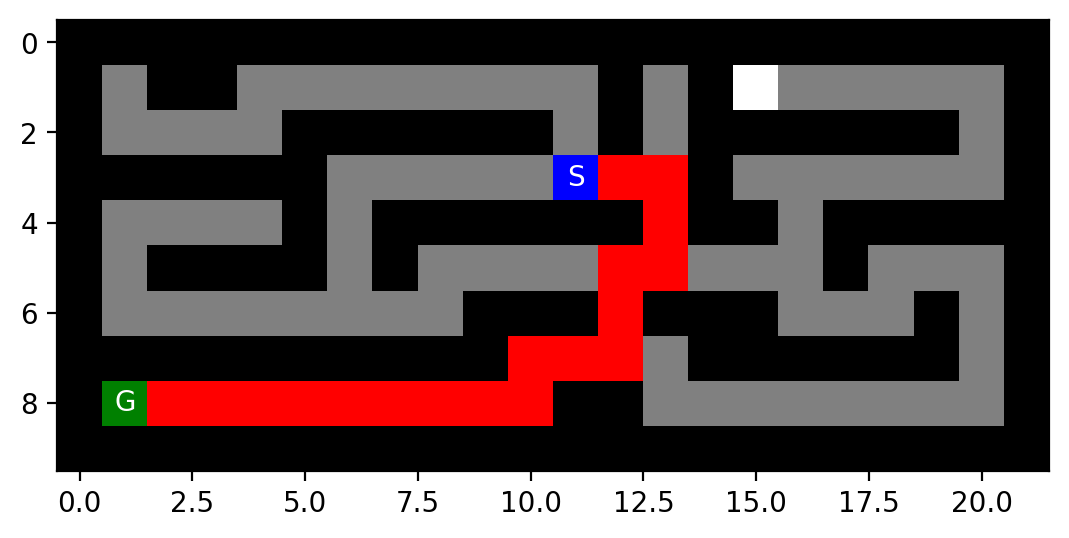

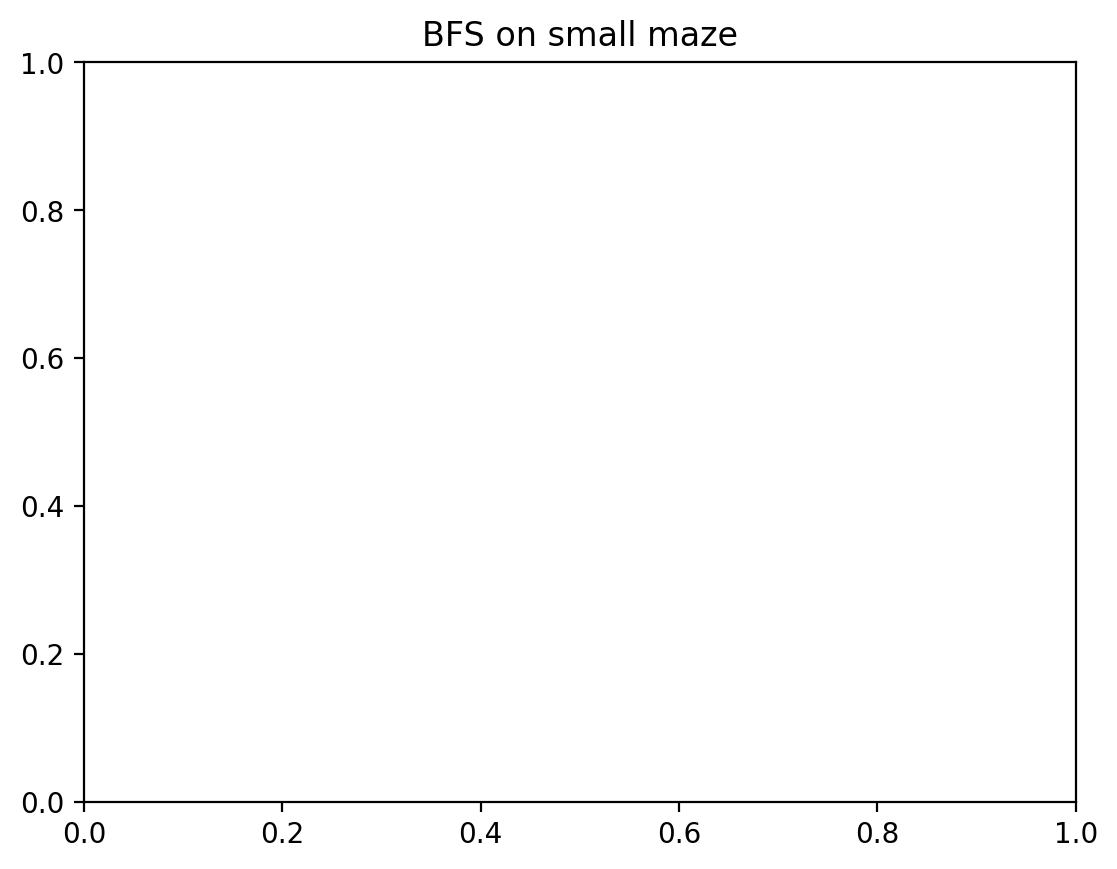

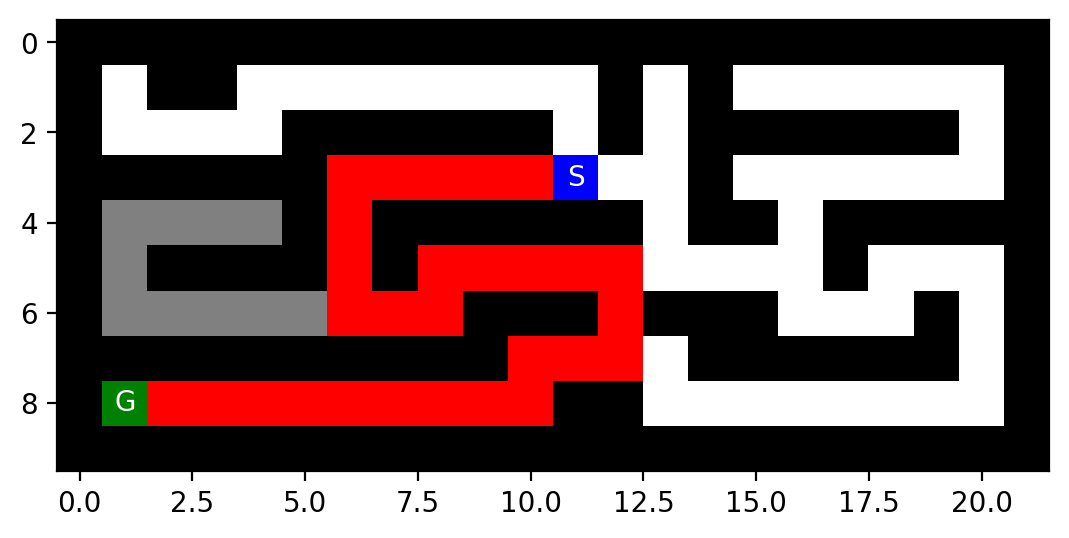

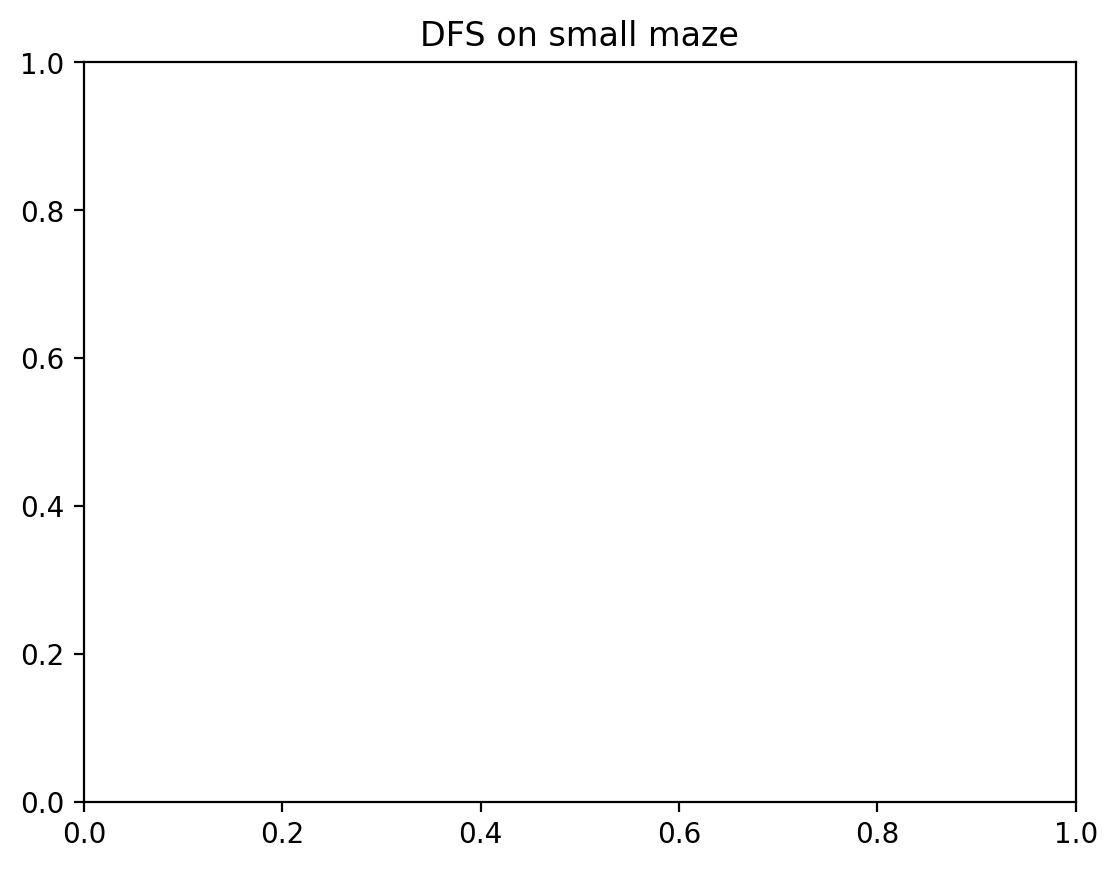

In [17]:
#Ve duong di BFS va DFS tren small maze
import matplotlib.pyplot as plt

def draw_result(maze, result, title):
    """Xám = ô đã khám phá, đỏ = đường đi cuối cùng."""
    m = np.copy(maze)
    for pos in result.get("visited", ()):
        if m[pos] == ' ': m[pos] = '.'
    for node in (result["path"] or []):
        if m[node.pos] not in ('S', 'G'): m[node.pos] = 'P'
    mh.show_maze(m)
    plt.title(title)
    plt.show()

draw_result(maze_small, res_bfs, "BFS on small maze")
draw_result(maze_small, res_dfs, "DFS on small maze")

Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

# Discussion

=== BFS ===
- Complete? YES. BFS duyệt hết mọi nút ở độ sâu d, nên chắc chắn tìm được G nếu tồn tại.
- Optimal? YES với bước đi đều có cost = 1 (BFS = UCS khi mọi bước cùng cost).
- Time complexity: O(b^d) — duyệt toàn bộ cây đến độ sâu d.
- Space complexity: O(b^d) — phải lưu toàn bộ frontier + reached.

 === DFS (không reached) ===
- Complete? CÓ trong không gian hữu hạn như các mê cung này, nhờ kiểm tra chu trình (on_path) nên không có nhánh vô hạn.
  KHÔNG nếu bỏ kiểm tra chu trình (có thể lặp vô hạn) hoặc trong không gian vô hạn.
- Optimal? KHÔNG. DFS dừng ở nghiệm đầu tiên tìm được, có thể rất sâu.
- Time complexity: O(b^m) — m là độ sâu tối đa (có thể = n).
- Space complexity: O(b·m) — chỉ lưu frontier (stack) + path hiện tại.

=== So sánh space complexity BFS vs DFS ===
- BFS: O(b^d) — có thể CỰC LỚN với d lớn.
- DFS: O(b·m) — TUYẾN TÍNH theo độ sâu, NHỎ HƠN NHIỀU so với BFS.
- Đây là lý do chính khiến DFS hấp dẫn về mặt bộ nhớ, dù không tối ưu.

=== Cycle checking ===
- BFS dùng reached → mỗi trạng thái chỉ xử lý 1 lần → không bao giờ lặp.
- DFS không dùng reached → phải kiểm tra on_path để tránh quay lại ô đã đi qua trên CÙNG một đường. Tuy vậy vẫn có thể thăm lại 1 ô qua đường khác (mất thời gian).
Trong không gian mở (empty_maze), DFS có thể mất rất nhiều thời gian vì số đường đi tăng theo hàm mũ.


## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides). 

In [18]:
def best_first(maze, start, goal, f):
    t = time.perf_counter()
    root = Node(start, None, None, 0); cnt = 0
    frontier = [(f(root, goal), cnt, root)]; reached = {root.pos: root}
    exp = maxd = 0; maxf = 1
    while frontier:
        _, _, n = heapq.heappop(frontier); exp += 1
        if n.pos == goal:
            return make_result(n, exp, maxd, maxf, time.perf_counter()-t, len(reached), reached)
        for ch in expand(maze, n):
            if ch.pos not in reached or ch.cost < reached[ch.pos].cost:
                reached[ch.pos] = ch; cnt += 1
                heapq.heappush(frontier, (f(ch, goal), cnt, ch)); maxd = max(maxd, ch.cost)
        maxf = max(maxf, len(frontier))
    return make_result(None, exp, maxd, maxf, time.perf_counter()-t, len(reached), reached)
gbfs  = lambda m, s, g: best_first(m, s, g, lambda n, g: manhattan(n.pos, g))
astar = lambda m, s, g: best_first(m, s, g, lambda n, g: n.cost + manhattan(n.pos, g))

=== GBFS trên small maze ===
Cost: 29, Expanded: 40, Max depth: 29, Max frontier: 5, Time: 0.28 ms

=== A* trên small maze ===
Cost: 19, Expanded: 54, Max depth: 19, Max frontier: 8, Time: 0.31 ms


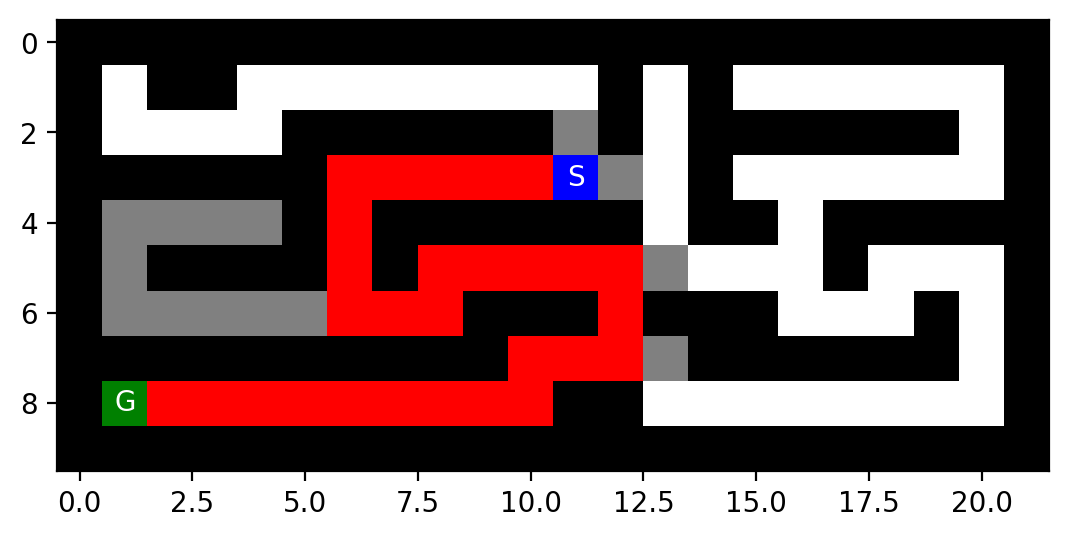

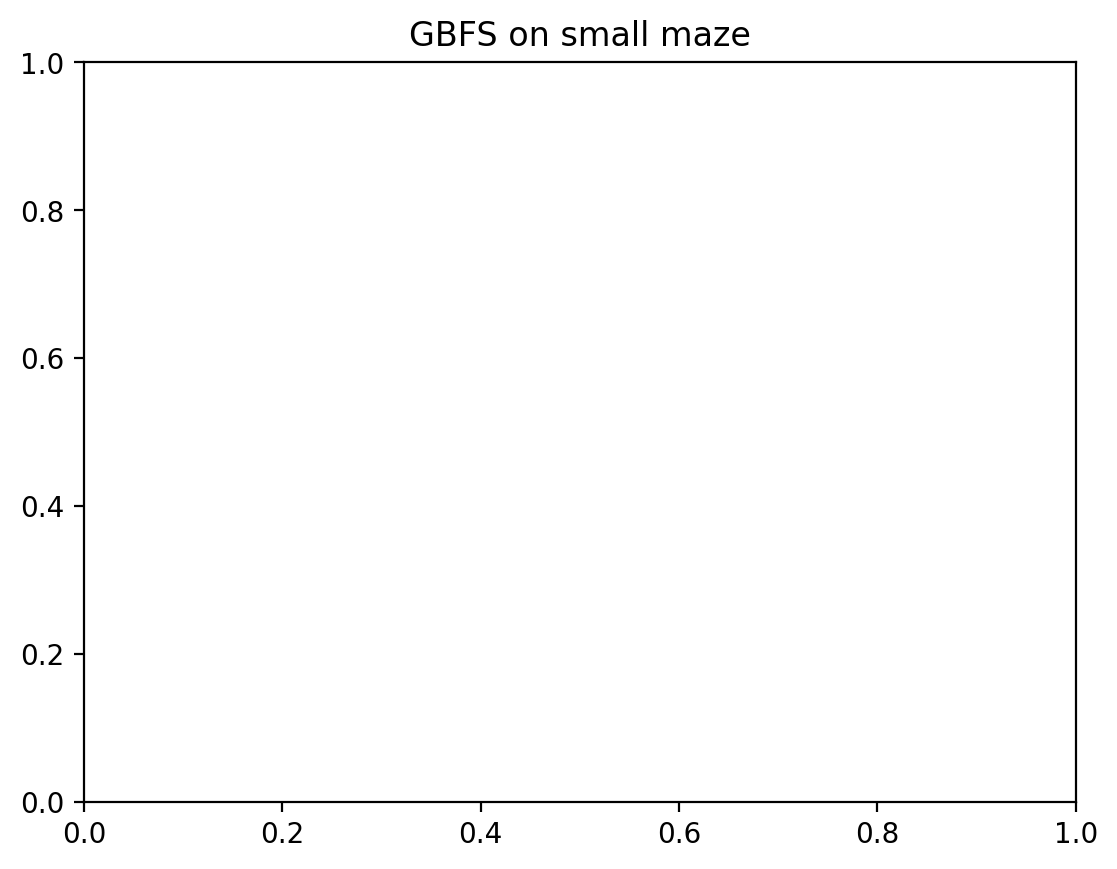

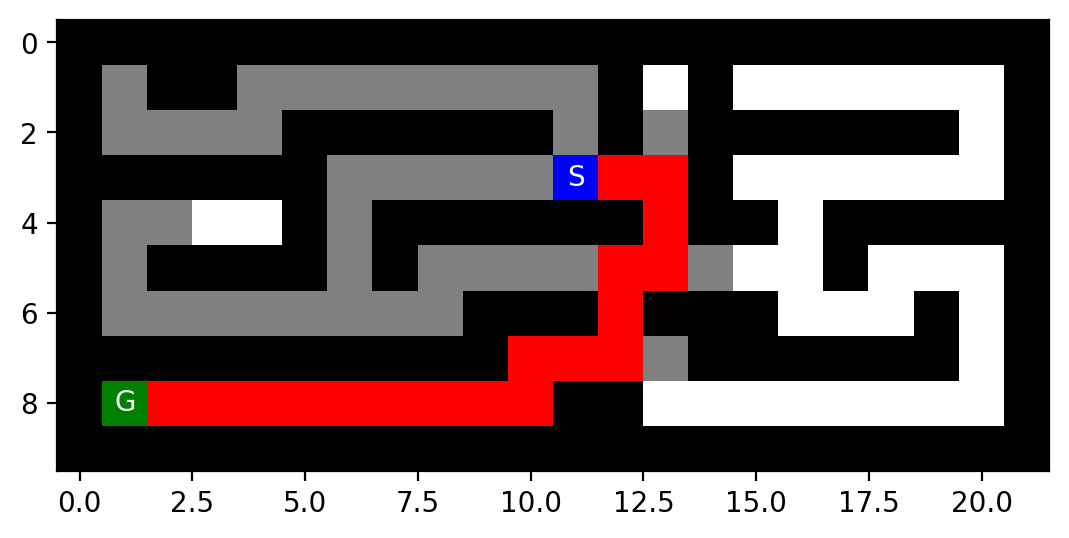

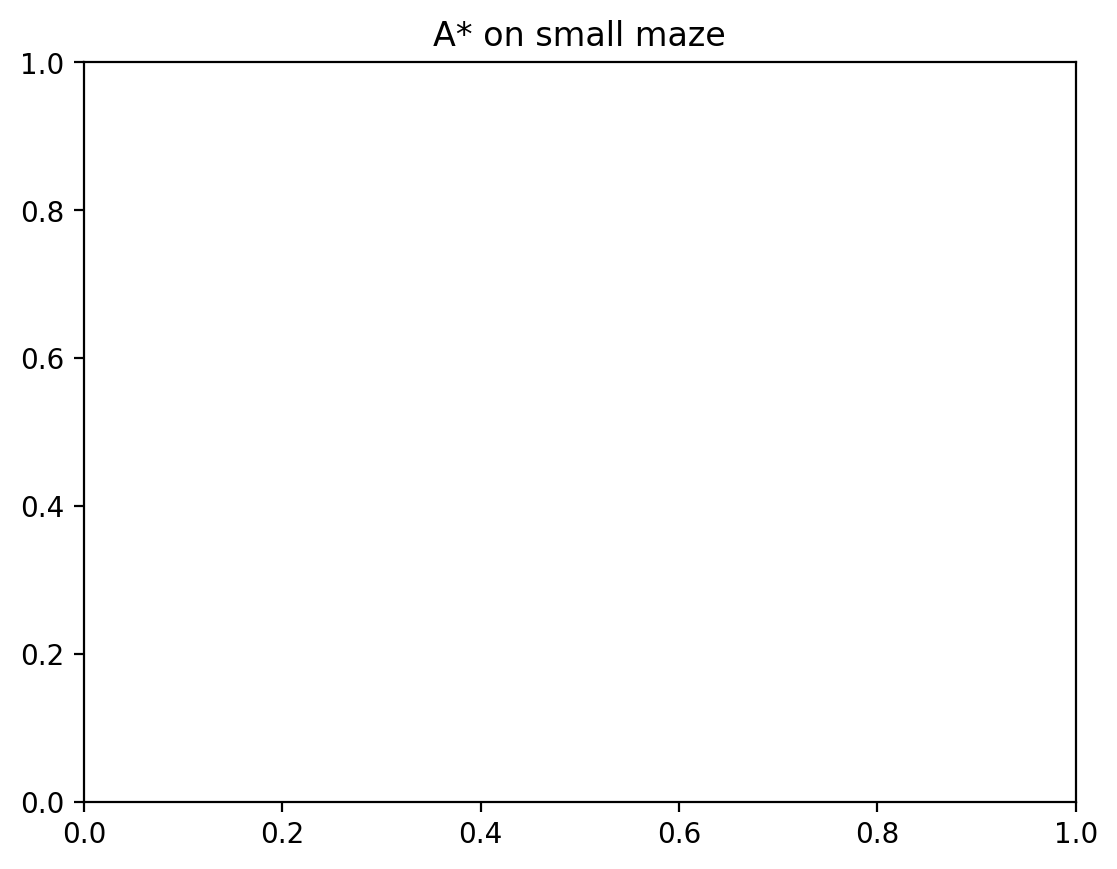

In [19]:
#Chạy GBFS và A* trên small maze
print("=== GBFS trên small maze ===")
res_gbfs = gbfs(maze_small, s_small, g_small)
print(f"Cost: {res_gbfs['cost']}, Expanded: {res_gbfs['expanded']}, "
      f"Max depth: {res_gbfs['max_depth']}, Max frontier: {res_gbfs['max_frontier']}, "
      f"Time: {res_gbfs['time']*1000:.2f} ms")

print("\n=== A* trên small maze ===")
res_astar = astar(maze_small, s_small, g_small)
print(f"Cost: {res_astar['cost']}, Expanded: {res_astar['expanded']}, "
      f"Max depth: {res_astar['max_depth']}, Max frontier: {res_astar['max_frontier']}, "
      f"Time: {res_astar['time']*1000:.2f} ms")

draw_result(maze_small, res_gbfs, "GBFS on small maze")
draw_result(maze_small, res_astar, "A* on small maze")

Are your implementations complete and optimal? What is the time and space complexity?

# Discussion

## 1. GBFS (Greedy Best-First Search)

- **Complete?** YES trong không gian hữu hạn có `reached`, nhưng có thể bị dẫn vào ngõ cụt nếu heuristic đánh lừa.
- **Optimal?** NO. GBFS chỉ quan tâm đến `h(n)`, bỏ qua `g(n)`, nên có thể chọn đường đi có vẻ gần đích nhưng chi phí thực tế lại cao.
- **Time complexity:** O(b^m) trong trường hợp xấu nhất, nhưng thường nhanh hơn BFS nhờ heuristic.
- **Space complexity:** O(b^m), do phải lưu các nút đã khám phá và frontier.

## 2. A* (A-Star Search)

- **Complete?** YES nếu chi phí mỗi bước dương và các điều kiện tìm kiếm phù hợp được đảm bảo.
- **Optimal?** YES nếu heuristic `h(n)` admissible, nghĩa là không đánh giá cao hơn chi phí thực tế còn lại. Manhattan distance trên lưới 4 hướng là admissible.
- **Time complexity:** O(b^d) trong trường hợp xấu nhất theo cách phân tích thường dùng; thực tế phụ thuộc vào heuristic và bài toán.
- **Space complexity:** O(b^d) theo cách phân tích thường dùng. A* cần lưu frontier và các nút đã khám phá nên tốn nhiều bộ nhớ.

## 3. So sánh A* và GBFS

- A* có thể tìm được đường đi tối ưu, còn GBFS không đảm bảo tối ưu.
- GBFS thường mở rộng ít nút hơn vì chỉ ưu tiên heuristic `h(n)`.
- A* sử dụng `f(n) = g(n) + h(n)`, cân nhắc cả chi phí đã đi và ước lượng chi phí còn lại.
- Cả hai đều có thể tìm kiếm hiệu quả hơn BFS khi heuristic phù hợp.

## Task 4: Comparison and discussion [20 Points] 

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

In [20]:
import numpy as np
import pandas as pd

files = {"small": "small_maze.txt", "medium": "medium_maze.txt", "large": "large_maze.txt",
         "open": "open_maze.txt", "L": "L_maze.txt", "loops": "loops_maze.txt",
         "empty": "empty_maze.txt", "empty_2": "empty_maze_2.txt"}

algos = [("BFS", bfs),
         ("DFS", lambda m, s, g: dfs(m, s, g, max_tries=200000, track_visited=True)),
         ("GBFS", gbfs), ("A*", astar)]

mazes, results, rows = {}, {}, []
for name, fname in files.items():
    maze = mh.parse_maze(open(fname).read())
    s, g = mh.find_pos(maze, "S"), mh.find_pos(maze, "G")
    mazes[name] = maze
    for an, fn in algos:
        r = fn(maze, s, g)
        results[(name, an)] = r
        solved = r["path"] is not None            # không giải được trong giới hạn -> N/A*
        rows.append([name, an, r["cost"] if solved else np.nan, r["expanded"],
                     r["max_depth"], r["max_memory"], r["max_frontier"],
                     round(r["time"] * 1000, 2)])

df = pd.DataFrame(rows, columns=["Maze", "Algorithm", "Path cost", "Expanded", "Max depth",
                                 "Max memory", "Max frontier", "Time (ms)"])

# Bảng hiển thị: số nguyên, N/A* khi không giải được
df_show = df.copy()
for col in ["Path cost", "Expanded", "Max depth", "Max memory", "Max frontier"]:
    df_show[col] = df_show[col].map(lambda v: "N/A*" if pd.isna(v) else int(v))

for name in files:
    print(f"\n{name} maze")
    print(df_show[df_show.Maze == name].drop(columns="Maze").to_string(index=False))


small maze
Algorithm  Path cost  Expanded  Max depth  Max memory  Max frontier  Time (ms)
      BFS         19        90         19          93             9       0.55
      DFS         29        39         29          55            26       0.30
     GBFS         29        40         29          44             5       0.28
       A*         19        54         19          59             8       0.41

medium maze
Algorithm  Path cost  Expanded  Max depth  Max memory  Max frontier  Time (ms)
      BFS         68       267         68         270             9       1.73
      DFS        152       153        152         259           107       2.00
     GBFS         74        79         74          82             4       0.48
       A*         68       223         68         228             8       2.17

large maze
Algorithm  Path cost  Expanded  Max depth  Max memory  Max frontier  Time (ms)
      BFS        210       618        210         622             8       5.60
      DFS      

Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)). 

In [21]:
from IPython.display import Markdown, display

cols = ["path cost", "# of nodes expanded", "max tree depth",
        "max # of nodes in memory", "max frontier size", "time (ms)"]
src = ["Path cost", "Expanded", "Max depth", "Max memory", "Max frontier", "Time (ms)"]

md = ""
for name in files:
    md += f"**{name} maze**\n\n"
    md += "| algorithm | " + " | ".join(cols) + " |\n"
    md += "|" + "---|" * (len(cols) + 1) + "\n"
    for an in ["BFS", "DFS", "GBFS", "A*"]:
        row = df_show[(df_show.Maze == name) & (df_show.Algorithm == an)].iloc[0]
        md += f"| {an} | " + " | ".join(str(row[c]) for c in src) + " |\n"
    md += "\n"

display(Markdown(md))

**small maze**

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 19 | 90 | 19 | 93 | 9 | 0.55 |
| DFS | 29 | 39 | 29 | 55 | 26 | 0.3 |
| GBFS | 29 | 40 | 29 | 44 | 5 | 0.28 |
| A* | 19 | 54 | 19 | 59 | 8 | 0.41 |

**medium maze**

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 68 | 267 | 68 | 270 | 9 | 1.73 |
| DFS | 152 | 153 | 152 | 259 | 107 | 2.0 |
| GBFS | 74 | 79 | 74 | 82 | 4 | 0.48 |
| A* | 68 | 223 | 68 | 228 | 8 | 2.17 |

**large maze**

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 210 | 618 | 210 | 622 | 8 | 5.6 |
| DFS | 210 | 337 | 215 | 370 | 160 | 7.79 |
| GBFS | 210 | 467 | 210 | 487 | 21 | 7.32 |
| A* | 210 | 550 | 210 | 557 | 12 | 4.18 |

**open maze**

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 54 | 679 | 54 | 683 | 25 | 5.41 |
| DFS | 54 | 211 | 179 | 308 | 143 | 6.0 |
| GBFS | 68 | 90 | 68 | 155 | 66 | 0.71 |
| A* | 54 | 536 | 54 | 555 | 25 | 5.32 |

**L maze**

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 16 | 146 | 16 | 152 | 17 | 1.42 |
| DFS | 122 | 132 | 122 | 176 | 65 | 2.27 |
| GBFS | 24 | 50 | 24 | 59 | 31 | 0.43 |
| A* | 16 | 54 | 16 | 79 | 26 | 0.46 |

**loops maze**

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 23 | 70 | 23 | 72 | 8 | 0.76 |
| DFS | 27 | 30 | 27 | 48 | 21 | 0.47 |
| GBFS | 23 | 77 | 23 | 61 | 10 | 1.15 |
| A* | 23 | 60 | 23 | 62 | 6 | 0.52 |

**empty maze**

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 14 | 92 | 14 | 96 | 12 | 1.61 |
| DFS | 80 | 80 | 80 | 121 | 46 | 2.83 |
| GBFS | 14 | 15 | 14 | 43 | 29 | 0.4 |
| A* | 14 | 64 | 14 | 94 | 31 | 0.71 |

**empty_2 maze**

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 14 | 92 | 14 | 96 | 11 | 1.48 |
| DFS | 34 | 34 | 34 | 97 | 63 | 0.56 |
| GBFS | 14 | 15 | 14 | 43 | 29 | 0.26 |
| A* | 14 | 64 | 14 | 94 | 31 | 1.1 |



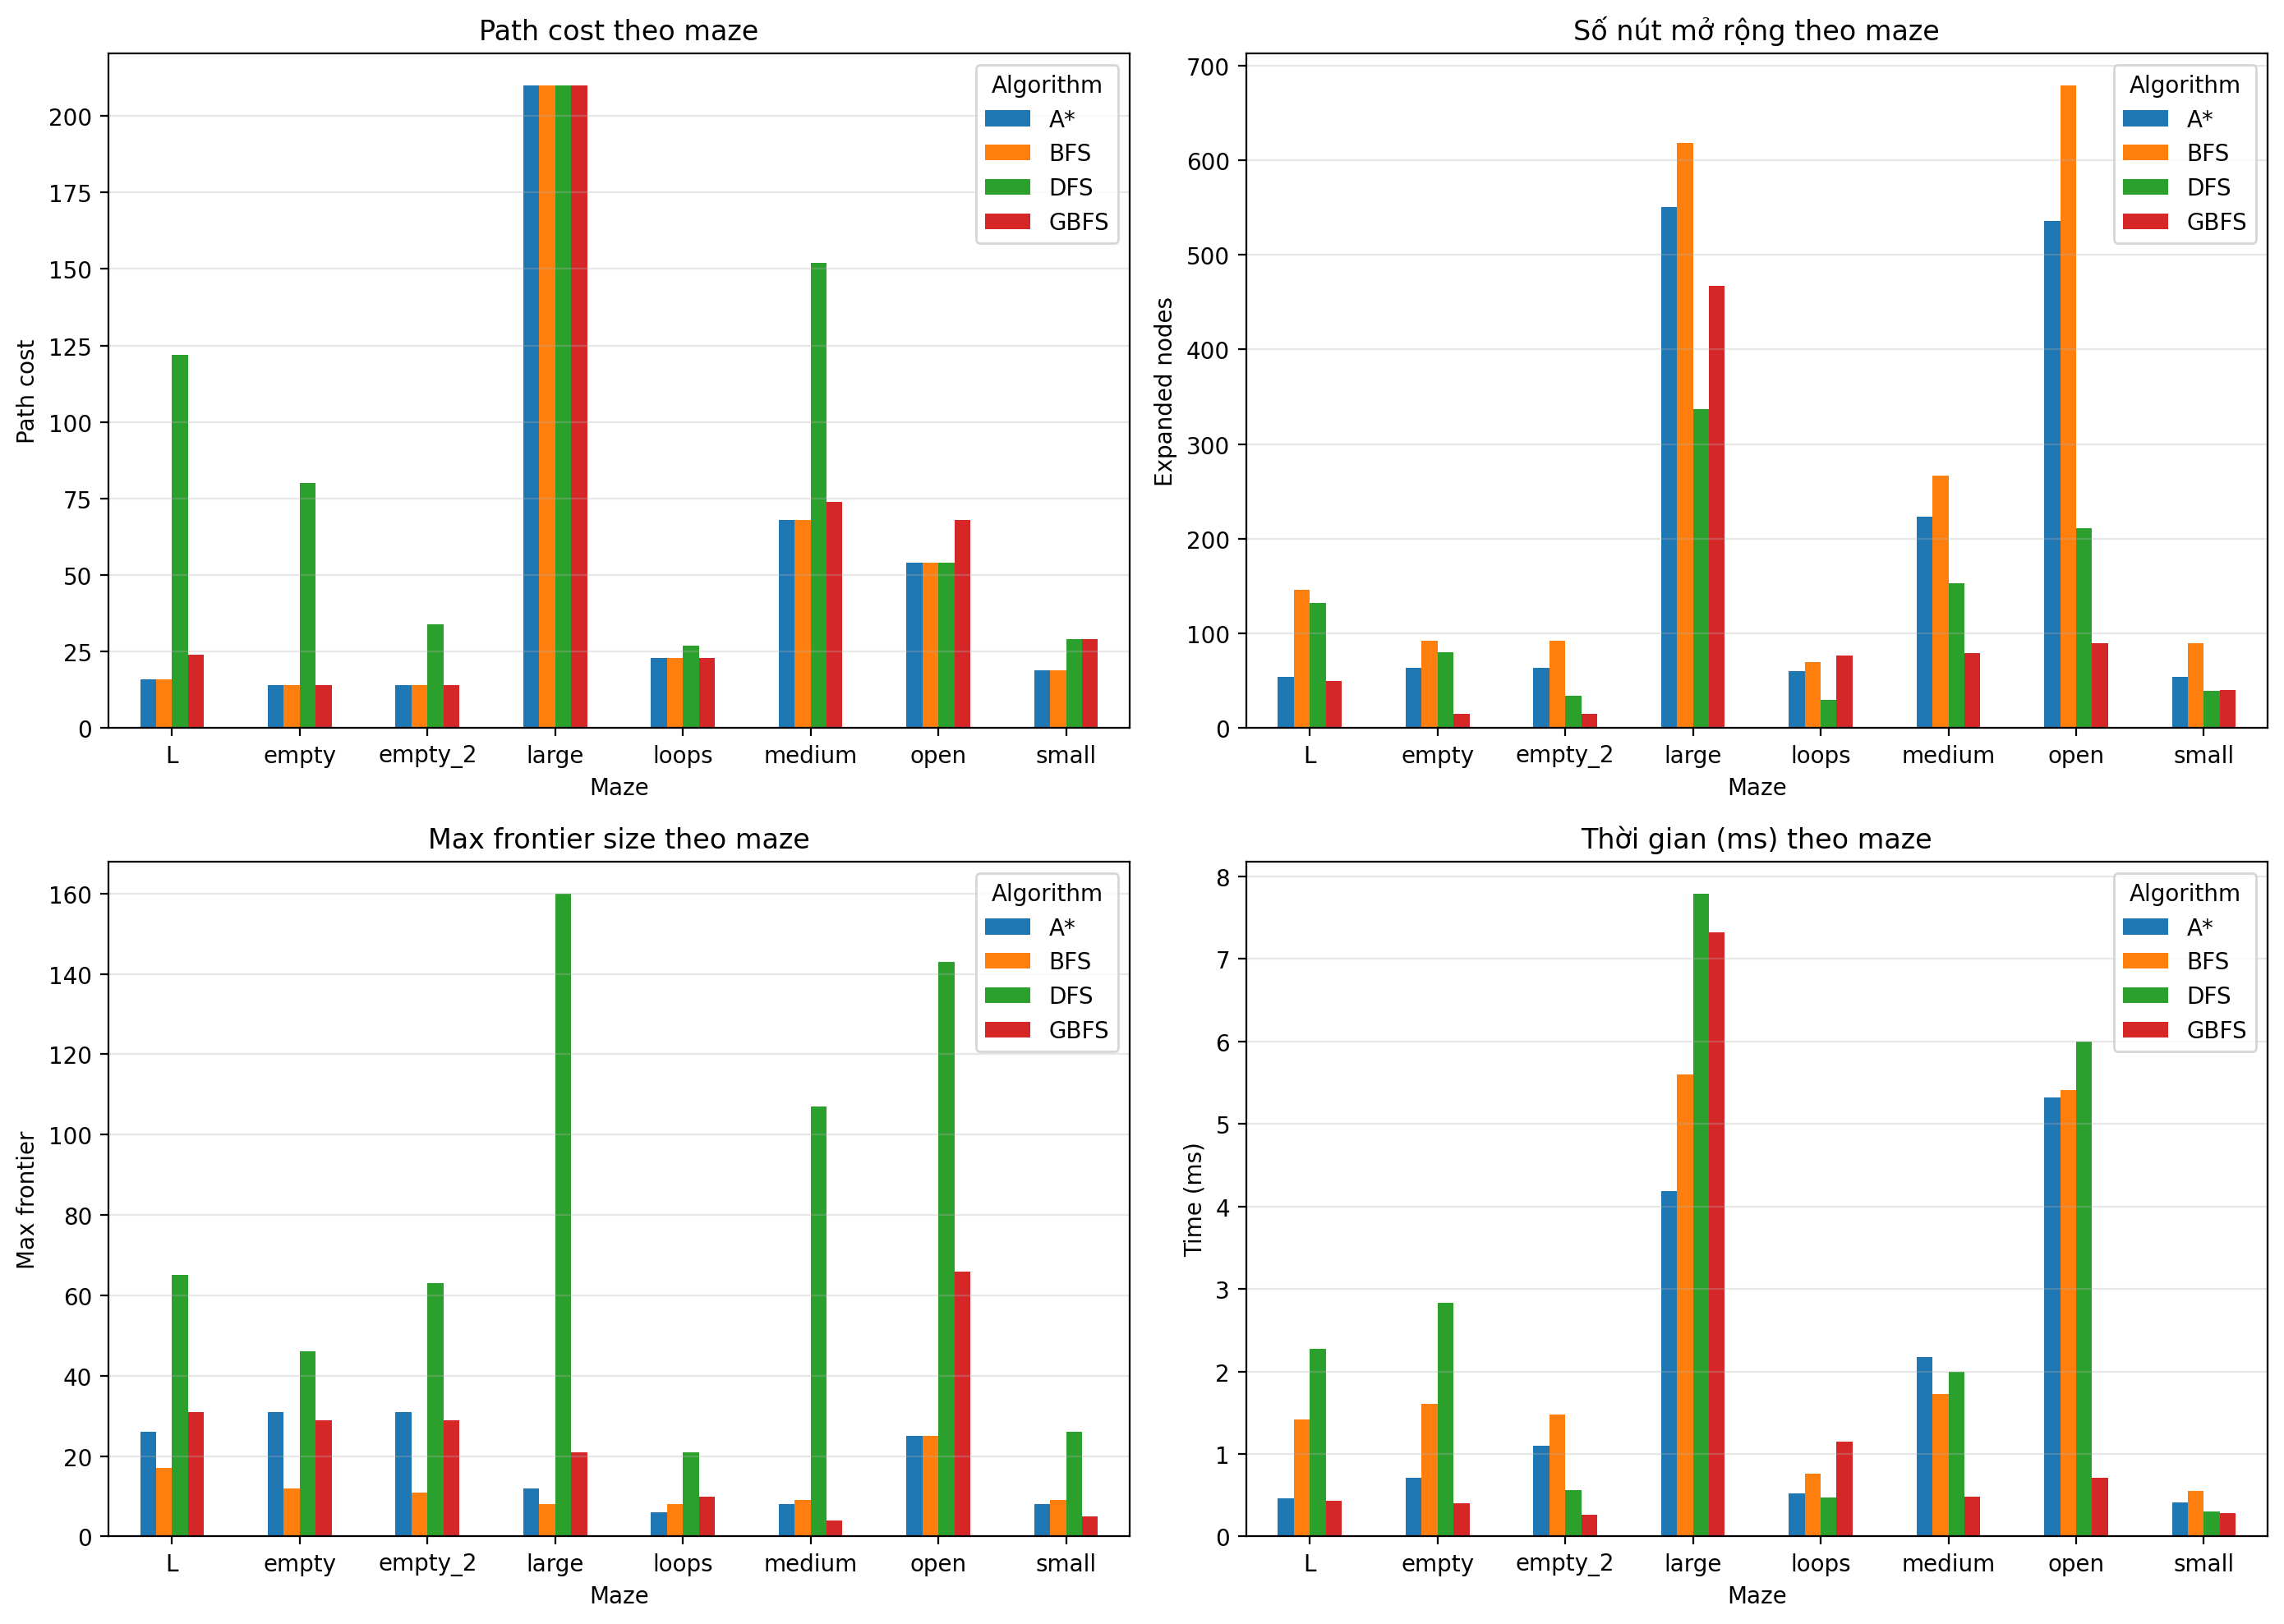

In [22]:
#Vẽ biểu đồ so sánh
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Lọc bỏ các dòng DFS có N/A (timeout)
df_valid = df.dropna(subset=["Path cost"])

# Chart 1: Path cost theo maze
pivot_cost = df_valid.pivot(index="Maze", columns="Algorithm", values="Path cost")
pivot_cost.plot(kind="bar", ax=axes[0, 0], rot=0)
axes[0, 0].set_title("Path cost theo maze")
axes[0, 0].set_ylabel("Path cost")
axes[0, 0].grid(axis="y", alpha=0.3)

# Chart 2: Số nút mở rộng theo maze
pivot_exp = df_valid.pivot(index="Maze", columns="Algorithm", values="Expanded")
pivot_exp.plot(kind="bar", ax=axes[0, 1], rot=0)
axes[0, 1].set_title("Số nút mở rộng theo maze")
axes[0, 1].set_ylabel("Expanded nodes")
axes[0, 1].grid(axis="y", alpha=0.3)

# Chart 3: Max frontier
pivot_front = df_valid.pivot(index="Maze", columns="Algorithm", values="Max frontier")
pivot_front.plot(kind="bar", ax=axes[1, 0], rot=0)
axes[1, 0].set_title("Max frontier size theo maze")
axes[1, 0].set_ylabel("Max frontier")
axes[1, 0].grid(axis="y", alpha=0.3)

# Chart 4: Time
pivot_time = df_valid.pivot(index="Maze", columns="Algorithm", values="Time (ms)")
pivot_time.plot(kind="bar", ax=axes[1, 1], rot=0)
axes[1, 1].set_title("Thời gian (ms) theo maze")
axes[1, 1].set_ylabel("Time (ms)")
axes[1, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("comparison_charts.png", dpi=120, bbox_inches="tight")
plt.show()

Discuss the most important lessons you have learned from implementing the different search strategies. 

# Discussion — Những bài học quan trọng

## 1. OPTIMALITY (Tính tối ưu)

- BFS: Tối ưu với mọi maze nếu chi phí mỗi bước bằng 1.
- A*: Tối ưu khi heuristic admissible và thuật toán được cài đặt phù hợp. Manhattan distance là admissible trên lưới 4 hướng.
- GBFS: Không đảm bảo tối ưu vì chỉ dựa vào heuristic `h(n)`. Đường đi tìm được có thể dài hơn BFS hoặc A*.
- DFS: Không đảm bảo tối ưu vì tìm nghiệm đầu tiên, không nhất thiết là nghiệm tốt nhất.

## 2. TIME COMPLEXITY (Độ phức tạp thời gian)

- GBFS: Thường mở rộng ít nút hơn khi heuristic tốt, phù hợp khi cần tìm lời giải nhanh nhưng không bắt buộc tối ưu.
- A*: Cân bằng giữa chi phí đã đi và chi phí ước lượng còn lại, thường hiệu quả khi heuristic phù hợp.
- BFS: Có thể mở rộng nhiều nút vì không sử dụng heuristic để định hướng tìm kiếm.
- DFS: Có thể tìm thấy nghiệm nhanh nếu đi đúng nhánh, nhưng có thể mất nhiều thời gian khi đi vào nhánh sâu hoặc không có nghiệm.

## 3. SPACE COMPLEXITY (Độ phức tạp bộ nhớ)

- BFS: Có thể cần O(b^d) bộ nhớ do phải lưu frontier và các nút đã khám phá.
- GBFS: Trong trường hợp xấu nhất có thể cần O(b^m) bộ nhớ.
- A*: Có thể tốn nhiều bộ nhớ để lưu frontier và các nút đã khám phá.
- DFS: Có thể sử dụng O(bm) bộ nhớ với cách cài đặt tìm kiếm theo chiều sâu đệ quy hoặc ngăn xếp và kiểm tra đường đi hiện tại.

Trong đó, `b` là hệ số phân nhánh, `d` là độ sâu của nghiệm nông nhất và `m` là độ sâu tối đa.

## 4. HEURISTIC (Hàm ước lượng)

- Manhattan distance phù hợp với lưới di chuyển 4 hướng, không đi chéo.
- Heuristic admissible không đánh giá cao hơn chi phí thực tế còn lại, giúp A* đảm bảo tính tối ưu khi các điều kiện cần thiết được đáp ứng.
- Heuristic consistent thỏa mãn bất đẳng thức nhất quán, giúp A* hạn chế việc phải mở lại các nút đã đóng khi cài đặt phù hợp.

## 5. CYCLE CHECKING (Kiểm tra chu trình)

- BFS, GBFS và A* thường sử dụng tập `reached` để tránh khám phá lại các trạng thái đã gặp.
- DFS có thể sử dụng `on_path` để tránh quay lại các trạng thái đang nằm trên đường đi hiện tại.
- Nếu không kiểm tra chu trình hoặc trạng thái đã thăm phù hợp, DFS có thể lặp lại vô hạn trong không gian có chu trình.
- IDS (Iterative Deepening Search) kết hợp ưu điểm tiết kiệm bộ nhớ của DFS với khả năng tìm nghiệm nông nhất khi mỗi bước có chi phí bằng nhau.

## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS 
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [23]:
#IDS (Iterative Deepening Search)
def ids(maze, start, goal, max_limit=None, max_nodes=None):
    """IDS = lặp DFS giới hạn độ sâu với limit = 0, 1, 2, ... (không có reached).
    max_nodes: ngân sách tổng số nút mở rộng; vượt quá thì dừng, trả path=None (báo N/A*)."""
    if max_limit is None:
        max_limit = int((maze != 'X').sum())          # chặn trên = số ô trống
    total_time = total_expanded = max_depth_seen = max_frontier_seen = 0
    for limit in range(max_limit + 1):
        t0 = time.perf_counter()
        frontier = [Node(start, None, None, 0)]
        expanded = maxd = 0; maxf = 1; found = None; aborted = False
        while frontier:
            n = frontier.pop(); expanded += 1
            maxd = max(maxd, n.cost)
            if n.pos == goal:
                found = n; break
            if max_nodes and total_expanded + expanded > max_nodes:
                aborted = True; break
            if n.cost >= limit:                        # chạm giới hạn độ sâu
                continue
            on_path = {x.pos for x in n.get_path_from_root()}   # kiểm tra chu trình
            for ch in expand(maze, n):
                if ch.pos not in on_path:
                    frontier.append(ch)
            maxf = max(maxf, len(frontier))
        total_time += time.perf_counter() - t0
        total_expanded += expanded
        max_depth_seen = max(max_depth_seen, maxd)
        max_frontier_seen = max(max_frontier_seen, maxf)
        if found is not None or aborted:
            return dict(path=found.get_path_from_root() if found else None,
                        cost=found.cost if found else None,
                        expanded=total_expanded, max_depth=max_depth_seen,
                        max_frontier=max_frontier_seen, time=total_time, limit=limit)
    return dict(path=None, cost=None, expanded=total_expanded, max_depth=max_depth_seen,
                max_frontier=max_frontier_seen, time=total_time, limit=max_limit)

In [ ]:
files_ids = {"small": "small_maze.txt", "medium": "medium_maze.txt", "large": "large_maze.txt",
             "open": "open_maze.txt", "L": "L_maze.txt", "loops": "loops_maze.txt",
             "empty": "empty_maze.txt", "empty_2": "empty_maze_2.txt"}

ids_rows, ids_results = [], {}
for name, fname in files_ids.items():
    m = mh.parse_maze(open(fname).read())
    s, g = mh.find_pos(m, "S"), mh.find_pos(m, "G")
    r = ids(m, s, g, max_nodes=3_000_000)
    ids_results[name] = r
    ok = r["path"] is not None
    ids_rows.append([name, r["cost"] if ok else "N/A*", r["limit"] if ok else "-",
                     r["expanded"], r["max_frontier"], round(r["time"] * 1000, 1)])

ids_df = pd.DataFrame(ids_rows, columns=["Maze", "Path cost", "Final limit", "Expanded (total)",
                                         "Max frontier", "Time (ms)"])
print(ids_df.to_string(index=False))

# Vẽ lời giải cho vài mê cung đã giải được
for name in ["small", "medium"]:
    m = mh.parse_maze(open(files_ids[name]).read())
    draw_result(m, ids_results[name], f"IDS on {name} maze")

### Thảo luận IDS

**Kết quả thực nghiệm:** IDS giải đúng và tối ưu (cùng cost với BFS) trên các mê cung hẹp (small, medium, large, loops).
Trên mê cung rỗng (empty, empty_2) vẫn giải được nhưng tốn 511–743 nghìn nút so với 92 nút của BFS.
Trên `open_maze` và `L_maze`, IDS vượt ngân sách 3 triệu nút nên ghi N/A*.

**Nguyên nhân:** IDS không có `reached`, chỉ kiểm tra chu trình trên đường đi hiện tại, nên cùng một ô bị thăm lại
qua rất nhiều đường khác nhau. Số đường đi tăng theo hàm mũ trong không gian mở, và mỗi lần tăng giới hạn
lại làm lại toàn bộ công việc của các lần trước.

### Multiple Goals 
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

In [ ]:
# === Kiểm tra tọa độ extra goals có phải ô trống không ===
maze_med = mh.parse_maze(open("medium_maze.txt").read())

# In ra một số ô trống gợi ý
empty_cells = [(r, c) for r in range(maze_med.shape[0])
               for c in range(maze_med.shape[1])
               if maze_med[r, c] == ' ']
print(f"Số ô trống trong medium maze: {len(empty_cells)}")
print(f"10 ô trống đầu tiên: {empty_cells[:10]}")
print(f"10 ô trống cuối cùng: {empty_cells[-10:]}")

# Kiểm tra 2 tọa độ dự kiến
for pos in [(8, 22), (4, 8)]:
    print(f"Ô {pos}: '{maze_med[pos]}'  (kỳ vọng: ' ')")

Số ô trống trong medium maze: 272
10 ô trống đầu tiên: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10)]
10 ô trống cuối cùng: [(16, 9), (16, 10), (16, 27), (16, 28), (16, 29), (16, 30), (16, 31), (16, 32), (16, 33), (16, 34)]
Ô (8, 22): ' '  (kỳ vọng: ' ')
Ô (4, 8): ' '  (kỳ vọng: ' ')


Số goal: 3
Danh sách goal: {(15, 27), (14, 8), (16, 1)}


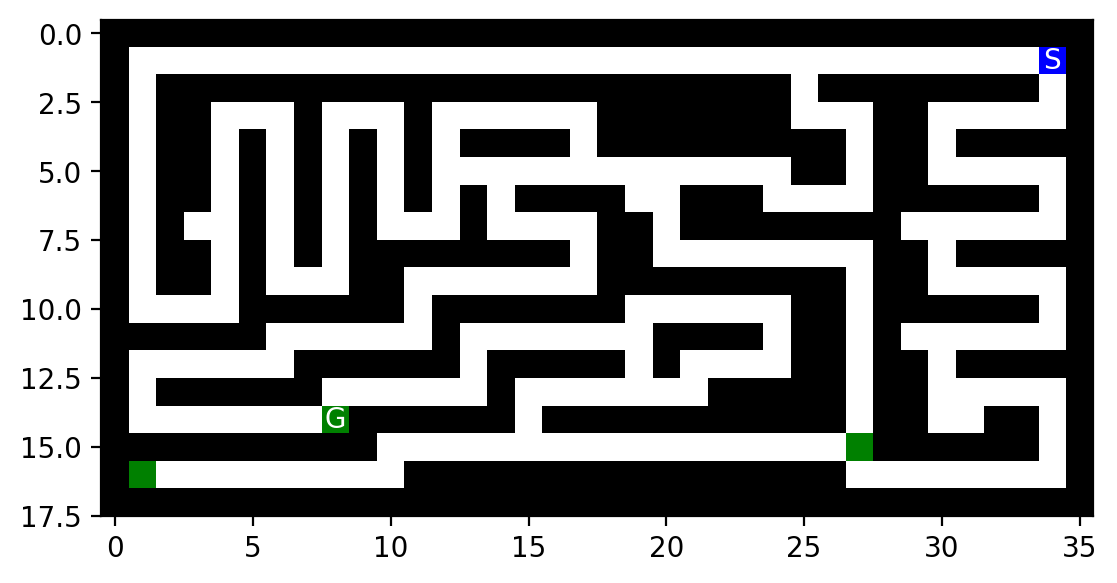

In [ ]:
# === Tạo maze với nhiều goal ===
extra_goals = [(8, 22), (4, 8)]
extra_goals = [(15, 27), (14, 8)]

def make_multi_goal_maze(maze, extra_goals):
    """Tạo maze mới với nhiều goal."""
    m = np.copy(maze)
    for g in extra_goals:
        if m[g] == ' ':
            m[g] = 'G'
    return m

maze_mg = make_multi_goal_maze(maze_med, extra_goals)

# Tìm tất cả goal trong maze mới
goals = set()
for r in range(maze_mg.shape[0]):
    for c in range(maze_mg.shape[1]):
        if maze_mg[r, c] == 'G':
            goals.add((r, c))

print(f"Số goal: {len(goals)}")
print(f"Danh sách goal: {goals}")

# Hiển thị maze với nhiều goal
%matplotlib inline
mh.show_maze(maze_mg)

In [ ]:
# === BFS với nhiều goal ===
def bfs_multi(maze, start, goals):
    t0 = time.perf_counter()
    root = Node(start, None, None, 0)
    if root.pos in goals:
        return dict(path=[root], cost=0, expanded=0,
                    max_depth=0, max_frontier=0,
                    time=time.perf_counter() - t0)
    frontier, reached = deque([root]), {root.pos}
    exp = maxd = 0
    maxf = 1
    while frontier:
        n = frontier.popleft()
        exp += 1
        for ch in expand(maze, n):
            if ch.pos in goals:
                return dict(path=ch.get_path_from_root(), cost=ch.cost,
                            expanded=exp, max_depth=max(maxd, ch.cost),
                            max_frontier=maxf,
                            time=time.perf_counter() - t0)
            if ch.pos not in reached:
                reached.add(ch.pos)
                frontier.append(ch)
                maxd = max(maxd, ch.cost)
        maxf = max(maxf, len(frontier))
    return dict(path=None, cost=None, expanded=exp, max_depth=maxd,
                max_frontier=maxf, time=time.perf_counter() - t0)


# === DFS với nhiều goal (cycle checking on-path) ===
def dfs_multi(maze, start, goals):
    t0 = time.perf_counter()
    frontier = [Node(start, None, None, 0)]
    exp = maxd = 0
    maxf = 1
    while frontier:
        n = frontier.pop()
        exp += 1
        maxd = max(maxd, n.cost)
        if n.pos in goals:
            return dict(path=n.get_path_from_root(), cost=n.cost,
                        expanded=exp, max_depth=maxd,
                        max_frontier=maxf,
                        time=time.perf_counter() - t0)
        on_path = {x.pos for x in n.get_path_from_root()}
        for ch in expand(maze, n):
            if ch.pos not in on_path:
                frontier.append(ch)
        maxf = max(maxf, len(frontier))
    return dict(path=None, cost=None, expanded=exp, max_depth=maxd,
                max_frontier=maxf, time=time.perf_counter() - t0)


# === IDS với nhiều goal ===
def ids_multi(maze, start, goals, max_limit=None):
    if max_limit is None:
        max_limit = int((maze != 'X').sum())
    total_t = total_e = 0
    for limit in range(max_limit + 1):
        t0 = time.perf_counter()
        frontier = [Node(start, None, None, 0)]
        expanded = 0
        while frontier:
            n = frontier.pop()
            expanded += 1
            if n.pos in goals:
                return dict(path=n.get_path_from_root(), cost=n.cost,
                            expanded=total_e + expanded,
                            max_depth=n.cost,
                            max_frontier=len(frontier),
                            time=total_t + time.perf_counter() - t0,
                            limit=limit)
            if n.cost >= limit:
                continue
            on_path = {x.pos for x in n.get_path_from_root()}
            for ch in expand(maze, n):
                if ch.pos not in on_path:
                    frontier.append(ch)
        total_t += time.perf_counter() - t0
        total_e += expanded
    return dict(path=None, cost=None, expanded=total_e,
                max_depth=None, max_frontier=None,
                time=total_t, limit=max_limit)

In [ ]:
# === Chạy BFS, DFS, IDS trên multi-goal maze ===
start_mg = mh.find_pos(maze_mg, "S")
print(f"Start: {start_mg}")
print(f"Goals: {goals}\n")

print("=== Multi-Goal Results ===")
print(f"{'Algorithm':<8} {'Path cost':>10} {'Expanded':>10} "
      f"{'Max depth':>10} {'Max frontier':>14} {'Time (ms)':>12}")

results_mg = {}
for an, fn in [("BFS", bfs_multi), ("DFS", dfs_multi), ("IDS", ids_multi)]:
    r = fn(maze_mg, start_mg, goals)
    results_mg[an] = r
    print(f"{an:<8} {str(r['cost']):>10} {str(r['expanded']):>10} "
          f"{str(r['max_depth']):>10} {str(r['max_frontier']):>14} "
          f"{r['time']*1000:>11.2f}")

Start: (np.int64(1), np.int64(34))
Goals: {(15, 27), (14, 8), (16, 1)}

=== Multi-Goal Results ===
Algorithm  Path cost   Expanded  Max depth   Max frontier    Time (ms)
BFS              41        148         41              9        1.90
DFS             115        117        115              5        2.46
IDS              41       3150         41              1       22.34


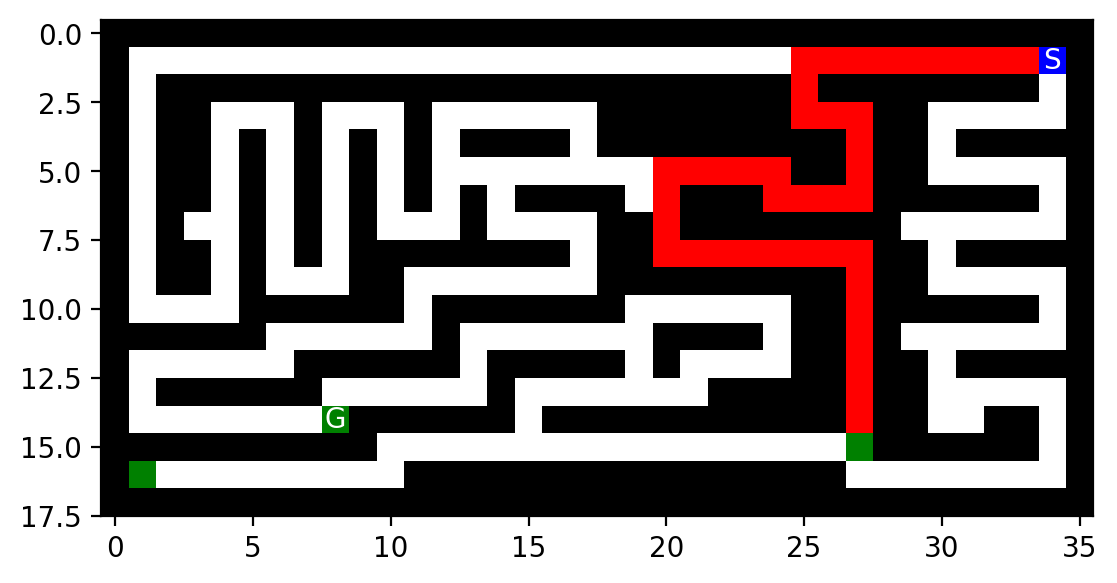

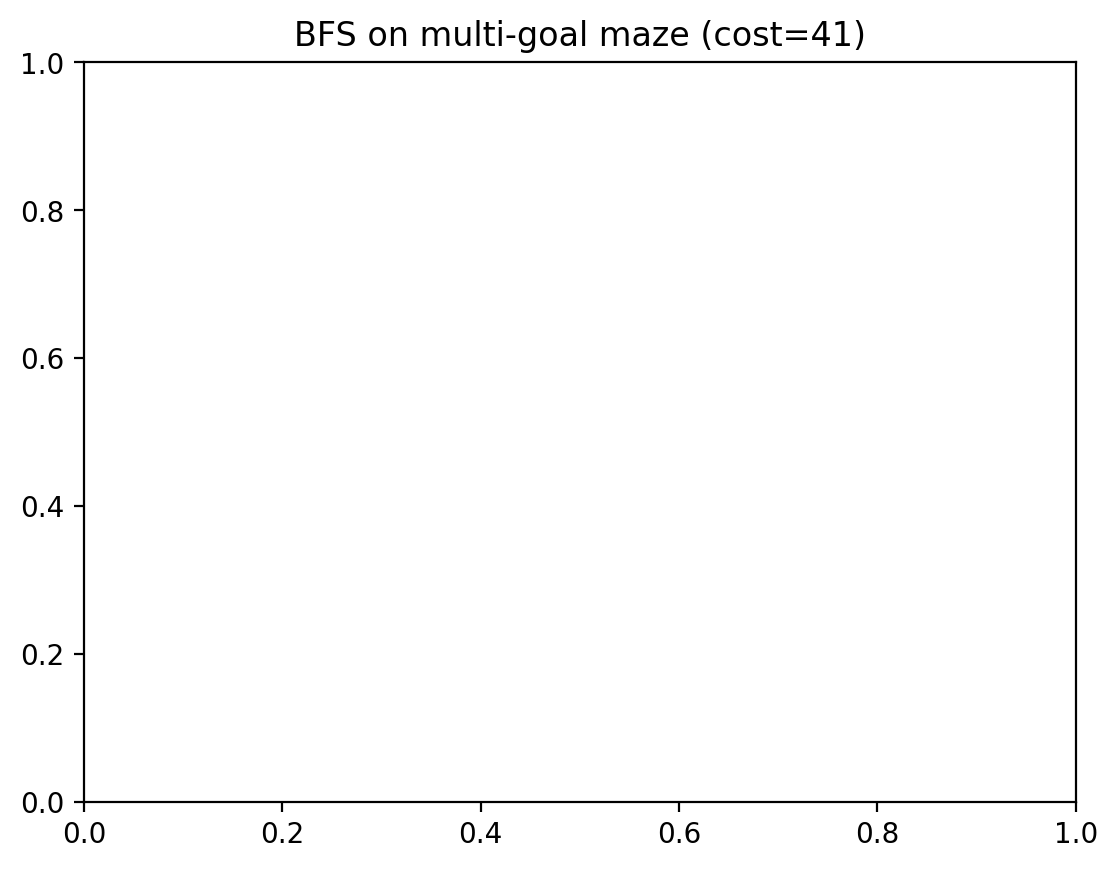

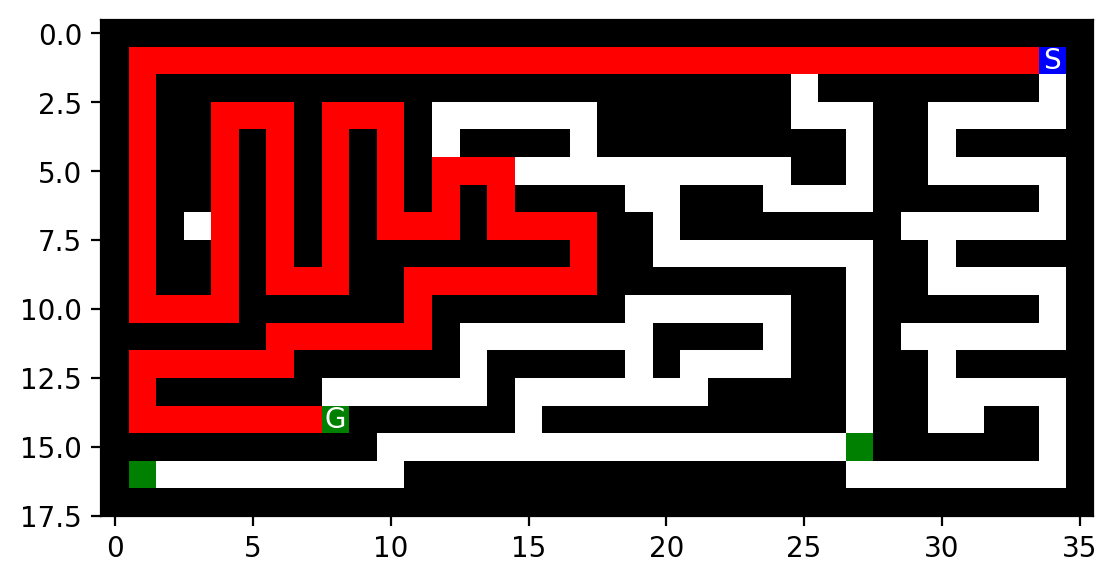

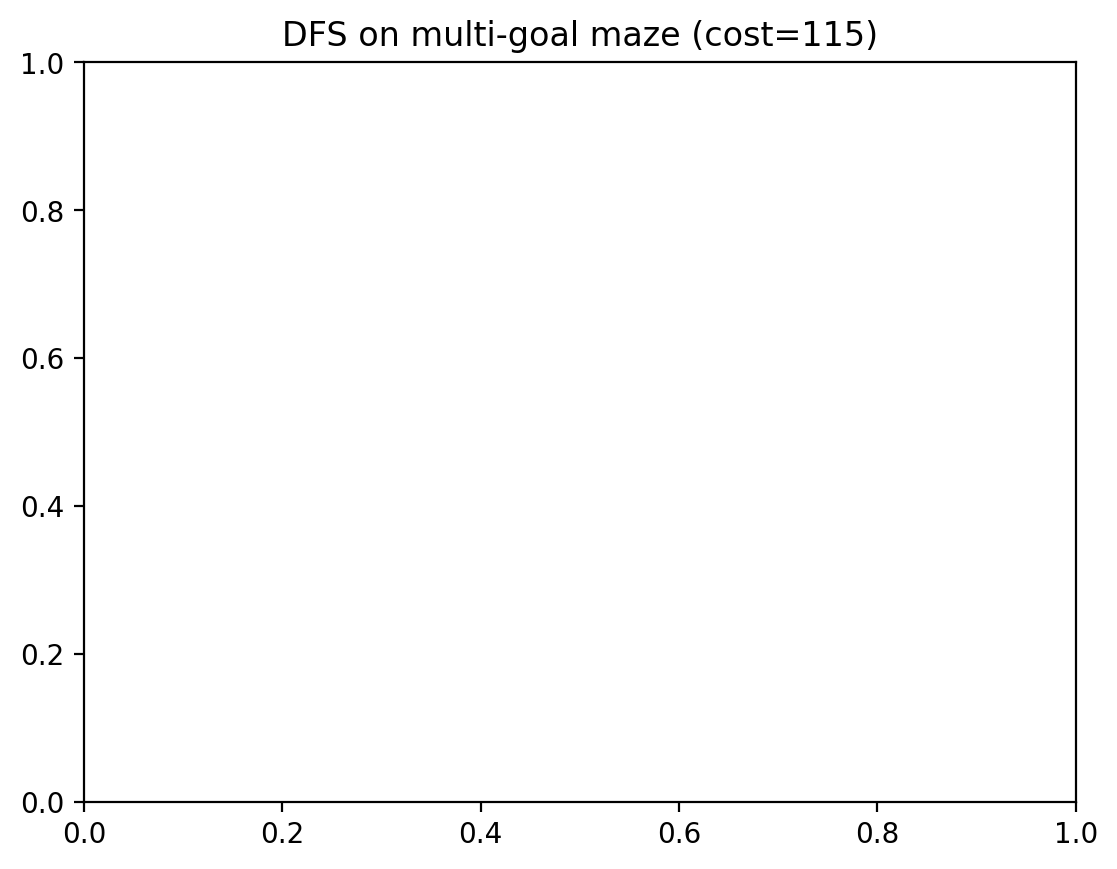

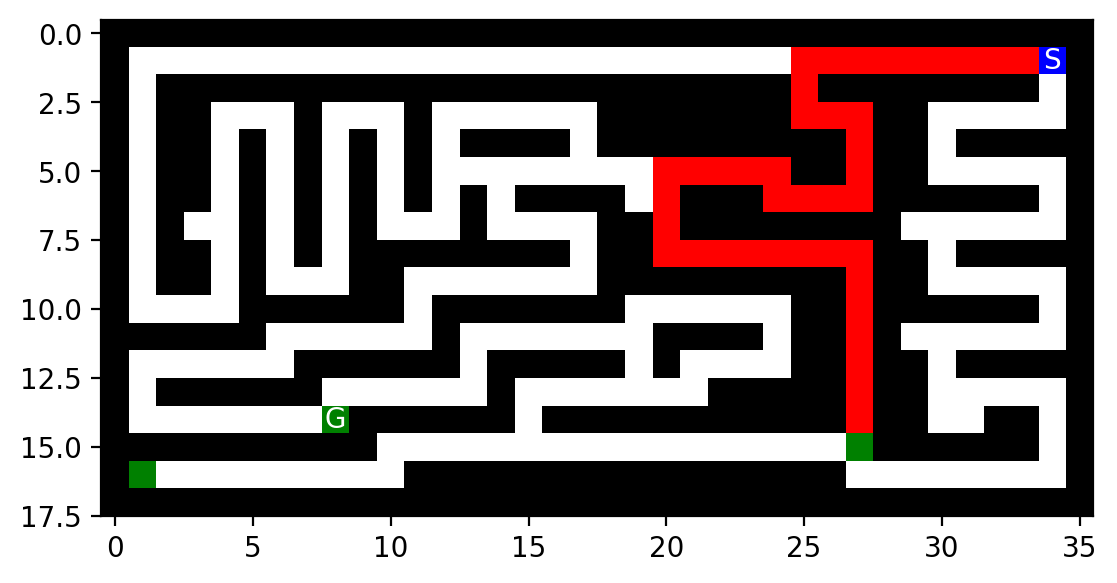

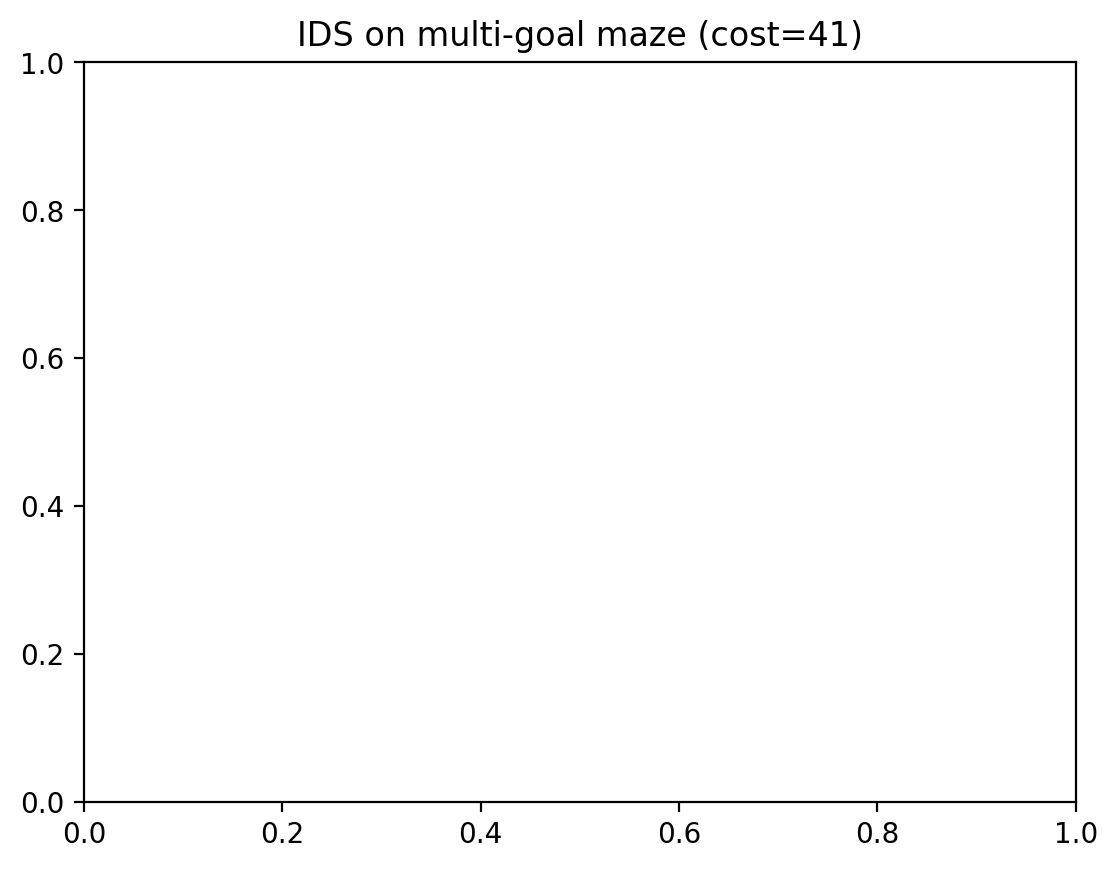

In [ ]:
# === Vẽ path tìm được trên multi-goal maze ===
import matplotlib.pyplot as plt

for an in ["BFS", "DFS", "IDS"]:
    r = results_mg[an]
    if r['path'] is not None:
        draw_result(maze_mg, r, f"{an} on multi-goal maze (cost={r['cost']})")
    else:
        print(f"{an}: không tìm thấy đường đi.")

### Thảo luận Multiple Goals

**BFS:** Tìm được goal GẦN NHẤT theo số bước. **TỐI ƯU** vì mở rộng theo từng lớp độ sâu,
nên goal đầu tiên chạm tới chắc chắn có cost nhỏ nhất.

**DFS:** KHÔNG tối ưu. DFS đi sâu theo một nhánh, có thể chạm một goal ở rất sâu
dù có goal khác gần hơn nhiều. Kết quả phụ thuộc thứ tự mở rộng và thứ tự đưa vào
frontier (LIFO). Vì vậy path cost của DFS thường lớn hơn BFS đáng kể.

**IDS:** TỐI ƯU như BFS. IDS lặp DFS với limit tăng dần, nên goal đầu tiên tìm thấy
nằm ở độ sâu nhỏ nhất trong số các goal — chính là goal gần nhất.

**Kết luận:** Trong bài toán nhiều đích, BFS và IDS đảm bảo tối ưu (tìm goal gần nhất),
còn DFS thì không. Đây là minh chứng rõ ràng cho tính chất complete/optimal của từng thuật toán đã phân tích ở Task 2.

**kết quả thực nghiệm: DFS 67 so với BFS/IDS 29**


## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

In [ ]:
# Your code/answer goes here

### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [ ]:
maze_med = mh.parse_maze(open("medium_maze.txt").read())
def weighted_astar(maze, start, goal, w=2.0):
    """A* với trọng số w. w=1 → A* chuẩn. w>1 → nhanh hơn nhưng có thể không tối ưu."""
    t = time.perf_counter()
    root = Node(start, None, None, 0)
    cnt = 0
    h0 = manhattan(root.pos, goal)
    frontier = [(root.cost + w * h0, cnt, root)]
    reached = {root.pos: root}
    exp = maxd = 0
    maxf = 1
    while frontier:
        _, _, n = heapq.heappop(frontier)
        exp += 1
        if n.pos == goal:
            return make_result(n, exp, maxd, maxf, time.perf_counter() - t)
        for ch in expand(maze, n):
            if ch.pos not in reached or ch.cost < reached[ch.pos].cost:
                reached[ch.pos] = ch
                cnt += 1
                f = ch.cost + w * manhattan(ch.pos, goal)
                heapq.heappush(frontier, (f, cnt, ch))
                maxd = max(maxd, ch.cost)
        maxf = max(maxf, len(frontier))
    return make_result(None, exp, maxd, maxf, time.perf_counter() - t)


# So sánh w = 1.0, 1.5, 2.0, 3.0, 5.0 trên medium maze
for w in [1.0, 1.5, 2.0, 3.0, 5.0]:
    r = weighted_astar(maze_med, mh.find_pos(maze_med, "S"),
                       mh.find_pos(maze_med, "G"), w=w)
    print(f"w={w}: cost={r['cost']}, expanded={r['expanded']}, "
          f"time={r['time']*1000:.1f} ms")

w=1.0: cost=68, expanded=223, time=6.4 ms
w=1.5: cost=68, expanded=231, time=5.4 ms
w=2.0: cost=68, expanded=231, time=3.4 ms
w=3.0: cost=68, expanded=229, time=3.4 ms
w=5.0: cost=74, expanded=79, time=1.5 ms


### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

In [ ]:
# Your code/answer goes here